# 02. Análisis exploratorio del dataset analítico

Este notebook realiza el análisis exploratorio del dataset analítico construido a partir de MIMIC-IV.

**Unidad de análisis:** estancia en UCI (`stay_id`).

Se revisan:
- estructura y calidad de datos;
- duplicados y valores faltantes;
- variables demográficas y categóricas;
- duración de estancia;
- signos vitales y laboratorios;
- valores extremos;
- correlaciones;
- variable objetivo `los_gt_3d`;
- relaciones entre predictores y objetivo;
- posibles riesgos de fuga de información (*data leakage*).

> El EDA no elimina automáticamente observaciones extremas ni imputa faltantes. Esas decisiones se tomarán posteriormente durante el preprocesamiento.


### Objetivo
Realizar un análisis exploratorio completo del dataset analítico construido a partir de MIMIC-IV, evaluando su estructura, calidad, distribuciones, valores faltantes, variables demográficas, signos vitales, laboratorios y posibles relaciones entre variables.

### Entrada
`data/interim/mimic_uci_12h_dataset_analitico.csv.gz`

Dataset generado por:

`01_construccion_dataset_analitico.ipynb`

### Análisis principales
- Dimensiones y tipos de variables.
- Identificación de duplicados.
- Análisis de valores faltantes.
- Distribución de la variable objetivo.
- Análisis de variables demográficas.
- Análisis de signos vitales.
- Análisis de laboratorios.
- Identificación de valores extremos.
- Correlaciones y asociaciones entre variables.
- Revisión de posibles riesgos de fuga de información.

### Salida
Resultados exploratorios utilizados para justificar la selección de variables del modelo.

### Siguiente etapa
`03_seleccion_variables.ipynb`


## 1. Librerías y carga del dataset


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import sys
from pathlib import Path

def encontrar_raiz_proyecto():
    actual = Path.cwd().resolve()
    for candidato in [actual, *actual.parents]:
        if (candidato / "src" / "config.py").exists():
            return candidato
    raise FileNotFoundError(
        "No se encontró la raíz del proyecto. "
        "Ejecuta este notebook dentro del repositorio estancia-hospitalaria-uci."
    )

PROJECT_ROOT = encontrar_raiz_proyecto()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import INTERIM_DIR

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RUTA = INTERIM_DIR / "mimic_uci_12h_dataset_analitico.csv.gz"

df = pd.read_csv(RUTA)

print("Archivo:", RUTA)
print(f"Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas")
display(df.head())


Archivo: C:\Users\grise\Downloads\estancia-hospitalaria-uci\data\interim\mimic_uci_12h_dataset_analitico.csv.gz
Dimensiones: 90,467 filas × 54 columnas


,subject_id,hadm_id,stay_id,los,los_restante_dias,edad_ingreso,gender,first_careunit,admission_type,admission_location,fc_min,fr_min,pad_min,pam_min,pas_min,spo2_min,temperatura_min,fc_mean,fr_mean,pad_mean,pam_mean,pas_mean,spo2_mean,temperatura_mean,fc_max,fr_max,pad_max,pam_max,pas_max,spo2_max,temperatura_max,lab_50868_anion_gap,lab_50882_bicarbonate,lab_50893_calcium_total,lab_50902_chloride,lab_50912_creatinine,lab_50931_glucose,lab_50960_magnesium,lab_50970_phosphate,lab_50971_potassium,lab_50983_sodium,lab_51006_urea_nitrogen,lab_51221_hematocrit,lab_51222_hemoglobin,lab_51237_inr_pt,lab_51248_mch,lab_51249_mchc,lab_51250_mcv,lab_51265_platelet_count,lab_51274_pt,lab_51275_ptt,lab_51277_rdw,lab_51279_red_blood_cells,lab_51301_white_blood_cells
0,10000690,25860671,37081114,3.893252,3.393252,86,F,Medical Intensive Care Unit (MICU),EW EMER.,EMERGENCY ROOM,62.0,19.0,37.0,49.0,84.0,83.0,96.0,77.769231,22.615385,50.250000,65.833333,110.833333,96.615385,97.600000,102.0,27.0,71.0,82.0,138.0,100.0,99.1,11.0,26.0,9.0,104.0,0.9,77.0,1.5,3.9,4.4,137.0,21.0,28.5,9.5,NaN,30.8,33.2,93.0,199.0,NaN,NaN,16.4,3.07,7.5
1,10001217,24597018,37067082,1.118032,0.618032,55,F,Surgical Intensive Care Unit (SICU),EW EMER.,EMERGENCY ROOM,78.0,18.0,72.0,83.0,127.0,93.0,98.5,91.153846,22.076923,82.230769,95.076923,137.692308,97.307692,98.850000,106.0,27.0,123.0,130.0,151.0,99.0,99.2,15.0,23.0,8.2,104.0,0.4,113.0,1.9,3.2,3.6,138.0,9.0,33.6,11.2,1.2,27.5,33.2,83.0,285.0,12.6,33.1,14.1,4.05,19.0
2,10001217,27703517,34592300,0.948113,0.448113,55,F,Surgical Intensive Care Unit (SICU),DIRECT EMER.,PHYSICIAN REFERRAL,69.0,11.0,61.0,68.0,99.0,90.0,97.6,80.142857,15.357143,76.307692,87.000000,122.384615,94.071429,97.866667,96.0,19.0,97.0,114.0,167.0,100.0,98.2,13.0,24.0,8.5,106.0,0.5,113.0,1.8,4.1,4.3,139.0,10.0,37.5,12.3,1.1,27.1,32.7,83.0,299.0,12.4,32.3,14.0,4.53,8.4
3,10001725,25563031,31205490,1.338588,0.838588,46,F,Medical/Surgical Intensive Care Unit (MICU/SICU),EW EMER.,PACU,55.0,15.0,45.0,54.0,73.0,94.0,97.7,79.307692,17.461538,61.769231,69.230769,96.230769,97.833333,97.700000,91.0,21.0,83.0,91.0,113.0,100.0,97.7,16.0,24.0,9.1,102.0,0.8,152.0,2.8,4.0,3.5,138.0,18.0,36.3,12.6,1.0,31.6,34.7,91.0,299.0,11.0,29.4,11.9,3.98,20.1
4,10001843,26133978,39698942,0.825266,0.325266,76,M,Medical/Surgical Intensive Care Unit (MICU/SICU),URGENT,TRANSFER FROM HOSPITAL,90.0,16.0,30.0,42.0,72.0,88.0,97.5,122.307692,21.153846,63.615385,70.153846,93.692308,95.538462,97.666667,155.0,26.0,85.0,90.0,114.0,99.0,97.9,16.0,20.0,8.2,101.0,1.7,108.0,2.2,7.5,5.4,137.0,33.0,31.6,9.1,2.1,28.1,28.8,98.0,609.0,23.5,42.0,22.1,3.24,10.5


## 2. Estructura general


In [2]:
print("Número de filas:", f"{df.shape[0]:,}")
print("Número de columnas:", df.shape[1])
print("\nTipos de datos:")
df.info()


Número de filas: 90,467
Número de columnas: 54

Tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90467 entries, 0 to 90466
Data columns (total 54 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   subject_id                   90467 non-null  int64  
 1   hadm_id                      90467 non-null  int64  
 2   stay_id                      90467 non-null  int64  
 3   los                          90467 non-null  float64
 4   los_restante_dias            90467 non-null  float64
 5   edad_ingreso                 90467 non-null  int64  
 6   gender                       90467 non-null  object 
 7   first_careunit               90467 non-null  object 
 8   admission_type               90467 non-null  object 
 9   admission_location           90467 non-null  object 
 10  fc_min                       90356 non-null  float64
 11  fr_min                       90078 non-null  float64
 12  pad_min   

In [3]:
resumen_columnas = pd.DataFrame({
    "variable": df.columns,
    "tipo": df.dtypes.astype(str).values,
    "n_unicos": df.nunique(dropna=True).values,
    "n_faltantes": df.isna().sum().values,
    "pct_faltantes": (df.isna().mean() * 100).values
}).sort_values("pct_faltantes", ascending=False)

display(resumen_columnas)


,variable,tipo,n_unicos,n_faltantes,pct_faltantes
50,lab_51275_ptt,float64,1249,25665,28.369461
44,lab_51237_inr_pt,float64,150,25466,28.149491
49,lab_51274_pt,float64,735,25459,28.141753
33,lab_50893_calcium_total,float64,136,21393,23.647297
38,lab_50970_phosphate,float64,149,21272,23.513546
36,lab_50931_glucose,float64,606,18728,20.701471
37,lab_50960_magnesium,float64,87,18552,20.506925
26,pad_max,float64,277,15293,16.904507
19,pad_mean,float64,8460,15293,16.904507
12,pad_min,float64,119,15293,16.904507


## 3. Identificadores y duplicados


In [4]:
print("Filas completamente duplicadas:", df.duplicated().sum())

for col in ["subject_id", "hadm_id", "stay_id"]:
    if col in df.columns:
        print(f"{col}: {df[col].nunique():,} únicos | {df[col].duplicated().sum():,} valores repetidos")

print("\nNota: subject_id y hadm_id pueden repetirse legítimamente; stay_id debe identificar una estancia de UCI.")


Filas completamente duplicadas: 0
subject_id: 63,487 únicos | 26,980 valores repetidos
hadm_id: 82,422 únicos | 8,045 valores repetidos
stay_id: 90,467 únicos | 0 valores repetidos

Nota: subject_id y hadm_id pueden repetirse legítimamente; stay_id debe identificar una estancia de UCI.


## 4. Valores faltantes


In [5]:
faltantes = pd.DataFrame({
    "n_faltantes": df.isna().sum(),
    "porcentaje": df.isna().mean() * 100
})

faltantes = faltantes[faltantes["n_faltantes"] > 0].sort_values("porcentaje", ascending=False)
display(faltantes)


,n_faltantes,porcentaje
lab_51275_ptt,25665,28.369461
lab_51237_inr_pt,25466,28.149491
lab_51274_pt,25459,28.141753
lab_50893_calcium_total,21393,23.647297
lab_50970_phosphate,21272,23.513546
lab_50931_glucose,18728,20.701471
lab_50960_magnesium,18552,20.506925
pad_max,15293,16.904507
pad_min,15293,16.904507
pad_mean,15293,16.904507


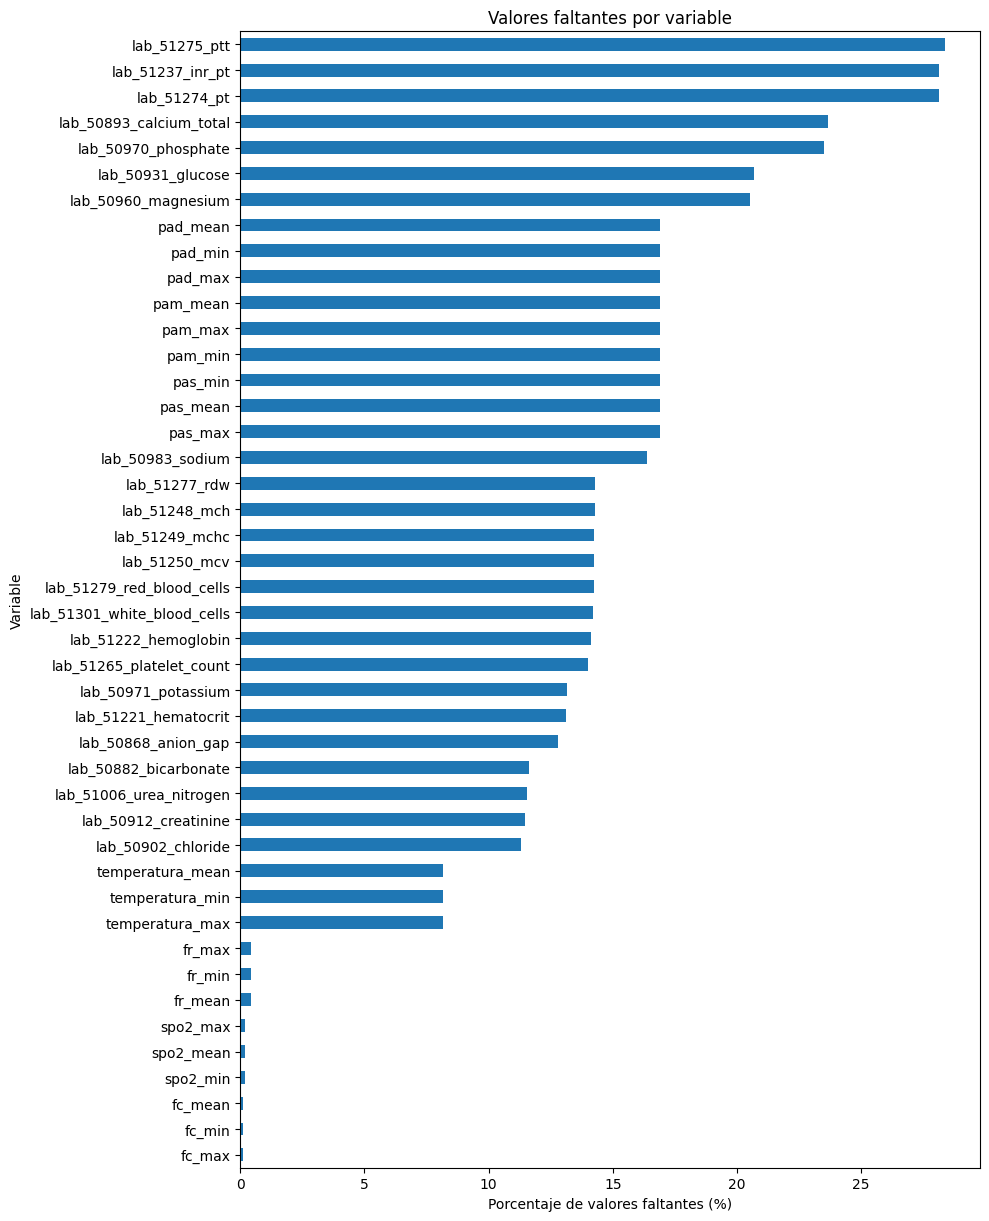

In [6]:
if not faltantes.empty:
    plt.figure(figsize=(10, max(5, len(faltantes)*0.28)))
    faltantes["porcentaje"].sort_values().plot(kind="barh")
    plt.xlabel("Porcentaje de valores faltantes (%)")
    plt.ylabel("Variable")
    plt.title("Valores faltantes por variable")
    plt.tight_layout()
    plt.show()


## 5. Clasificación de variables


In [7]:
ids = [c for c in ["subject_id", "hadm_id", "stay_id"] if c in df.columns]

categoricas = [
    c for c in ["gender", "first_careunit", "admission_type", "admission_location"]
    if c in df.columns
]

vitales = [
    c for c in df.columns
    if c.startswith(("fc_", "fr_", "pad_", "pam_", "pas_", "spo2_", "temperatura_"))
]

laboratorios = [c for c in df.columns if c.startswith("lab_")]

print("Identificadores:", len(ids))
print("Categóricas:", len(categoricas))
print("Signos vitales:", len(vitales))
print("Laboratorios:", len(laboratorios))
print("\nSignos vitales:", vitales)
print("\nLaboratorios:", laboratorios)


Identificadores: 3
Categóricas: 4
Signos vitales: 21
Laboratorios: 23

Signos vitales: ['fc_min', 'fr_min', 'pad_min', 'pam_min', 'pas_min', 'spo2_min', 'temperatura_min', 'fc_mean', 'fr_mean', 'pad_mean', 'pam_mean', 'pas_mean', 'spo2_mean', 'temperatura_mean', 'fc_max', 'fr_max', 'pad_max', 'pam_max', 'pas_max', 'spo2_max', 'temperatura_max']

Laboratorios: ['lab_50868_anion_gap', 'lab_50882_bicarbonate', 'lab_50893_calcium_total', 'lab_50902_chloride', 'lab_50912_creatinine', 'lab_50931_glucose', 'lab_50960_magnesium', 'lab_50970_phosphate', 'lab_50971_potassium', 'lab_50983_sodium', 'lab_51006_urea_nitrogen', 'lab_51221_hematocrit', 'lab_51222_hemoglobin', 'lab_51237_inr_pt', 'lab_51248_mch', 'lab_51249_mchc', 'lab_51250_mcv', 'lab_51265_platelet_count', 'lab_51274_pt', 'lab_51275_ptt', 'lab_51277_rdw', 'lab_51279_red_blood_cells', 'lab_51301_white_blood_cells']


## 6. Estadística descriptiva de variables numéricas


In [8]:
numericas = df.select_dtypes(include=np.number).columns

resumen_numerico = df[numericas].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T

display(resumen_numerico)


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
subject_id,90467.0,1.500666e+07,2.885467e+06,1.000069e+07,1.010944e+07,1.051248e+07,1.251708e+07,1.500680e+07,1.751984e+07,1.951025e+07,1.990430e+07,1.999999e+07
hadm_id,90467.0,2.498391e+07,2.885035e+06,2.000009e+07,2.010160e+07,2.049511e+07,2.248332e+07,2.498488e+07,2.746837e+07,2.950952e+07,2.990043e+07,2.999983e+07
stay_id,90467.0,3.499684e+07,2.887099e+06,3.000015e+07,3.009935e+07,3.048892e+07,3.250311e+07,3.499726e+07,3.749073e+07,3.950474e+07,3.989970e+07,3.999986e+07
los,90467.0,3.775706e+00,5.474029e+00,5.000000e-01,5.529088e-01,7.013924e-01,1.169844e+00,2.045810e+00,3.987008e+00,1.295221e+01,2.689731e+01,2.264031e+02
los_restante_dias,90467.0,3.275706e+00,5.474029e+00,0.000000e+00,5.290880e-02,2.013924e-01,6.698438e-01,1.545810e+00,3.487008e+00,1.245221e+01,2.639731e+01,2.259031e+02
edad_ingreso,90467.0,6.480405e+01,1.664438e+01,1.800000e+01,2.200000e+01,3.200000e+01,5.500000e+01,6.600000e+01,7.700000e+01,8.900000e+01,9.200000e+01,1.030000e+02
fc_min,90356.0,7.350668e+01,1.648233e+01,0.000000e+00,3.900000e+01,5.000000e+01,6.200000e+01,7.200000e+01,8.400000e+01,1.030000e+02,1.164500e+02,1.660000e+02
fr_min,90078.0,1.307590e+01,4.471935e+00,0.000000e+00,0.000000e+00,6.000000e+00,1.100000e+01,1.300000e+01,1.600000e+01,2.000000e+01,2.400000e+01,3.600000e+01
pad_min,75174.0,5.230159e+01,1.344706e+01,0.000000e+00,2.100000e+01,3.200000e+01,4.300000e+01,5.200000e+01,6.100000e+01,7.600000e+01,8.700000e+01,1.390000e+02
pam_min,75184.0,6.493222e+01,8.447678e+01,-2.276700e+04,3.200000e+01,4.400000e+01,5.600000e+01,6.400000e+01,7.400000e+01,9.000000e+01,1.020000e+02,2.240000e+02


## 7. Edad al ingreso


count    90467.000000
mean        64.804050
std         16.644385
min         18.000000
25%         55.000000
50%         66.000000
75%         77.000000
max        103.000000
Name: edad_ingreso, dtype: float64

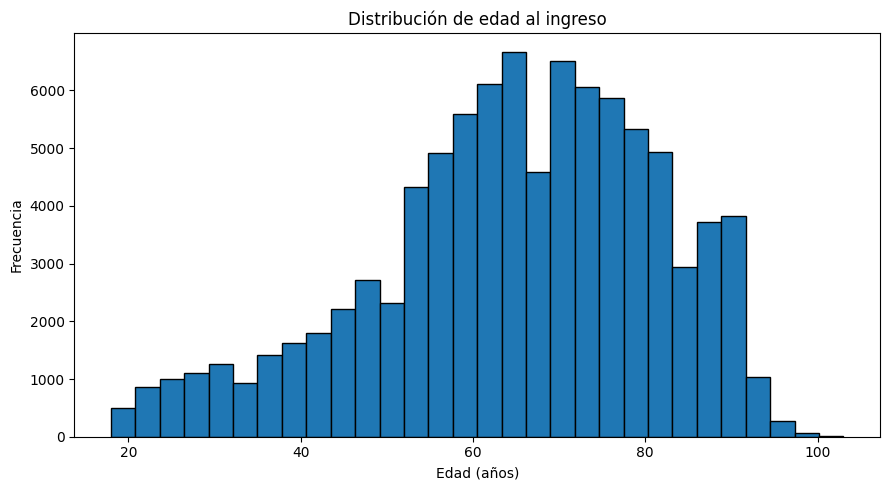

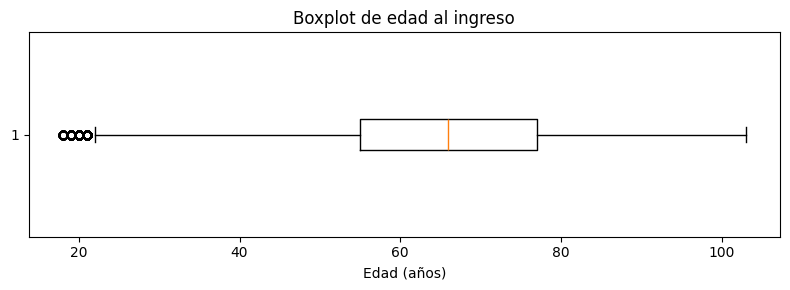

In [9]:
if "edad_ingreso" in df.columns:
    display(df["edad_ingreso"].describe())

    plt.figure(figsize=(9,5))
    plt.hist(df["edad_ingreso"].dropna(), bins=30, edgecolor="black")
    plt.xlabel("Edad (años)")
    plt.ylabel("Frecuencia")
    plt.title("Distribución de edad al ingreso")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(8,3))
    plt.boxplot(df["edad_ingreso"].dropna(), vert=False)
    plt.xlabel("Edad (años)")
    plt.title("Boxplot de edad al ingreso")
    plt.tight_layout()
    plt.show()


## 8. Variables categóricas



gender


,n,porcentaje
gender,,
M,50732,56.077907
F,39735,43.922093


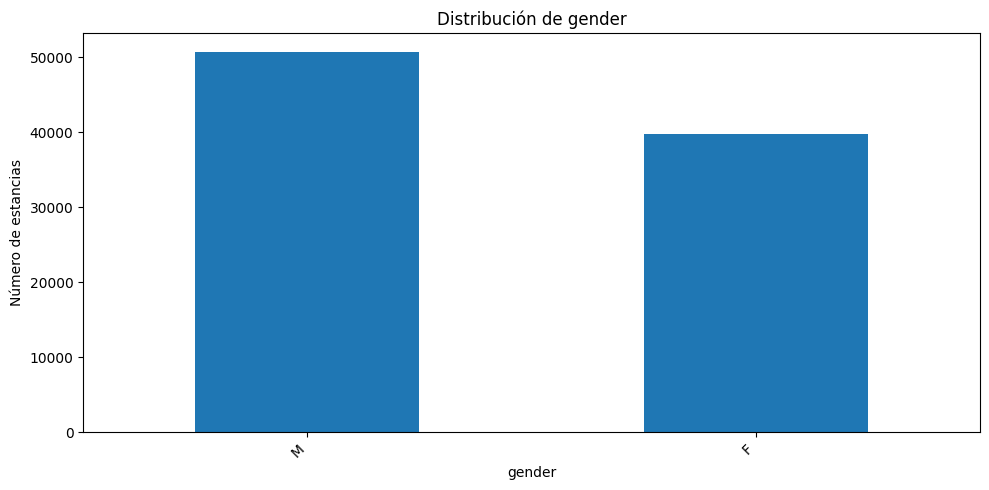


first_careunit


,n,porcentaje
first_careunit,,
Medical Intensive Care Unit (MICU),19744,21.824533
Medical/Surgical Intensive Care Unit (MICU/SICU),14656,16.200382
Cardiac Vascular Intensive Care Unit (CVICU),14461,15.984834
Surgical Intensive Care Unit (SICU),12509,13.827141
Coronary Care Unit (CCU),10214,11.290305
Trauma SICU (TSICU),9840,10.876894
Neuro Intermediate,5646,6.240950
Neuro Surgical Intensive Care Unit (Neuro SICU),1696,1.874717
Neuro Stepdown,1384,1.529840


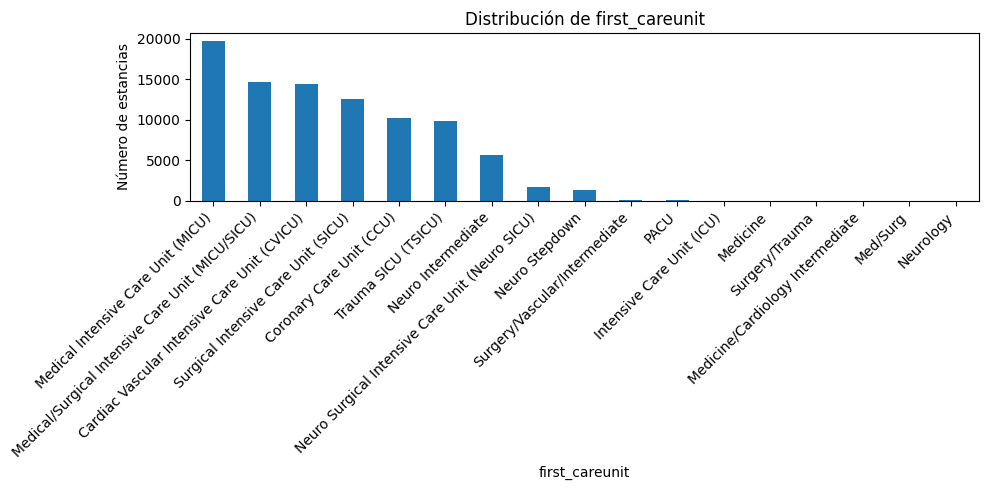


admission_type


,n,porcentaje
admission_type,,
EW EMER.,46066,50.920225
URGENT,14774,16.330817
OBSERVATION ADMIT,13482,14.902672
SURGICAL SAME DAY ADMISSION,9367,10.354052
DIRECT EMER.,3199,3.536096
ELECTIVE,2977,3.290703
EU OBSERVATION,413,0.456520
DIRECT OBSERVATION,172,0.190125
AMBULATORY OBSERVATION,17,0.018791


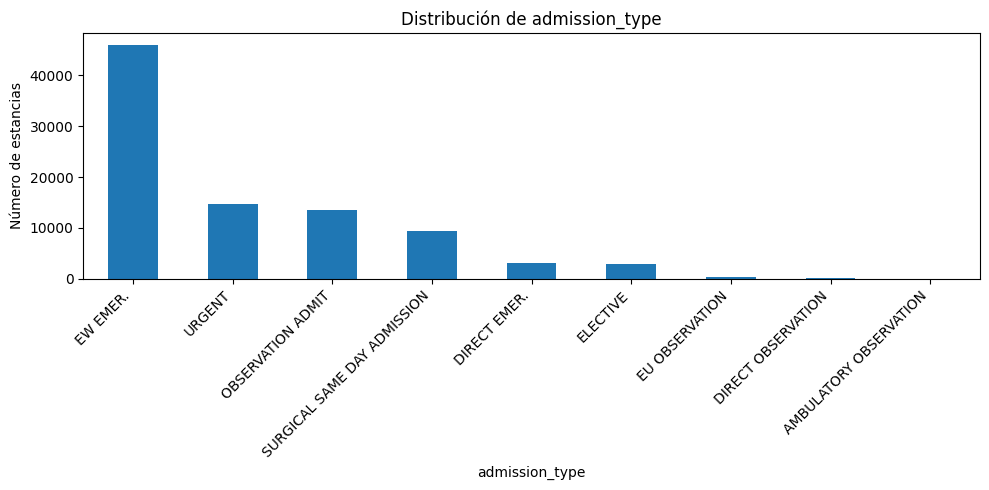


admission_location


,n,porcentaje
admission_location,,
EMERGENCY ROOM,35710,39.472957
TRANSFER FROM HOSPITAL,23314,25.770723
PHYSICIAN REFERRAL,22948,25.366156
WALK-IN/SELF REFERRAL,4248,4.695635
TRANSFER FROM SKILLED NURSING FACILITY,1416,1.565212
CLINIC REFERRAL,1131,1.250180
PROCEDURE SITE,991,1.095427
PACU,395,0.436623
INFORMATION NOT AVAILABLE,223,0.246499


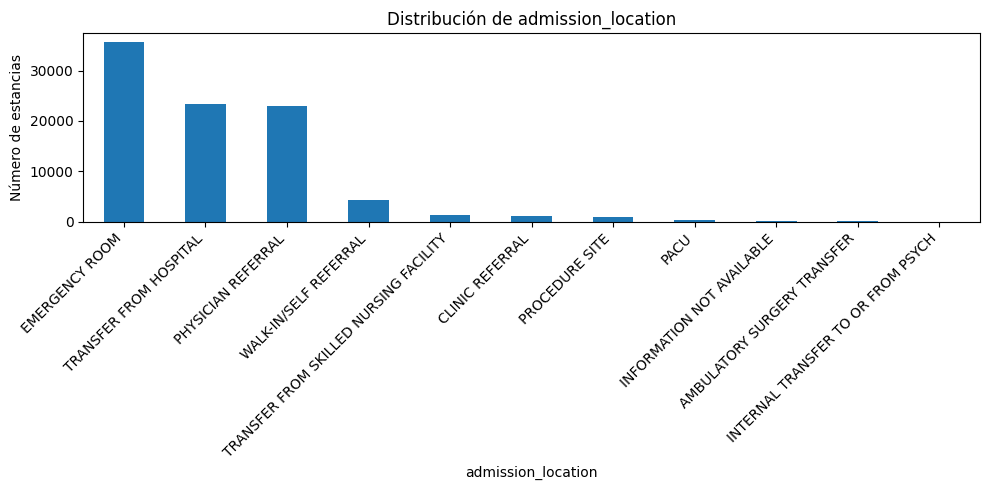

In [10]:
for col in categoricas:
    print("\n", "="*70)
    print(col)
    print("="*70)
    tabla = pd.DataFrame({
        "n": df[col].value_counts(dropna=False),
        "porcentaje": df[col].value_counts(dropna=False, normalize=True) * 100
    })
    display(tabla)

    plt.figure(figsize=(10,5))
    df[col].value_counts(dropna=False).plot(kind="bar")
    plt.xlabel(col)
    plt.ylabel("Número de estancias")
    plt.title(f"Distribución de {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


## 9. Duración de estancia (LOS)

`los` representa la duración total de la estancia en UCI.  
`los_restante_dias` representa la estancia restante después del punto de predicción de 12 horas.

Estas variables son útiles para describir el desenlace, pero **no deben utilizarse como predictores** si contienen información posterior a las primeras 12 horas.


,count,mean,std,min,1%,5%,25%,50%,75%,90%,95%,99%,max
los,90467.0,3.775706,5.474029,0.5,0.552909,0.701392,1.169844,2.04581,3.987008,8.136308,12.952206,26.897307,226.403079
los_restante_dias,90467.0,3.275706,5.474029,0.0,0.052909,0.201392,0.669844,1.54581,3.487008,7.636308,12.452206,26.397307,225.903079


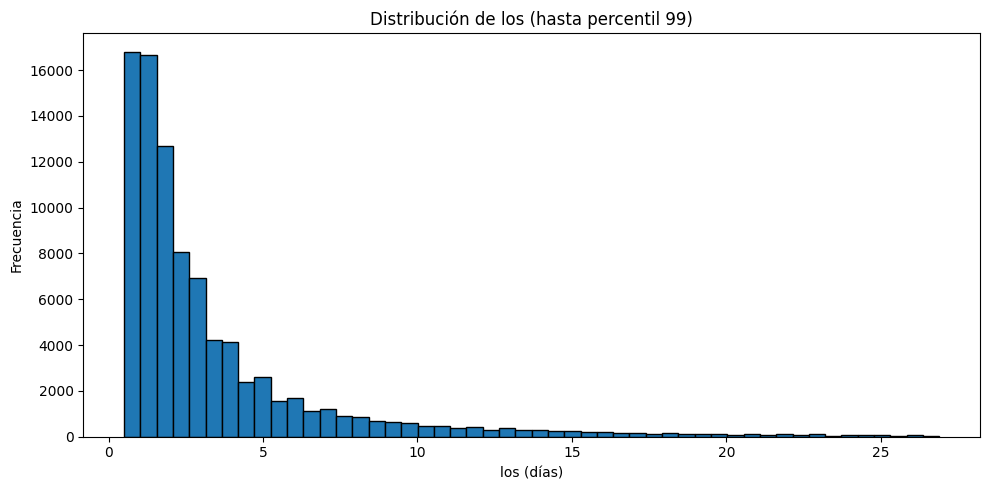

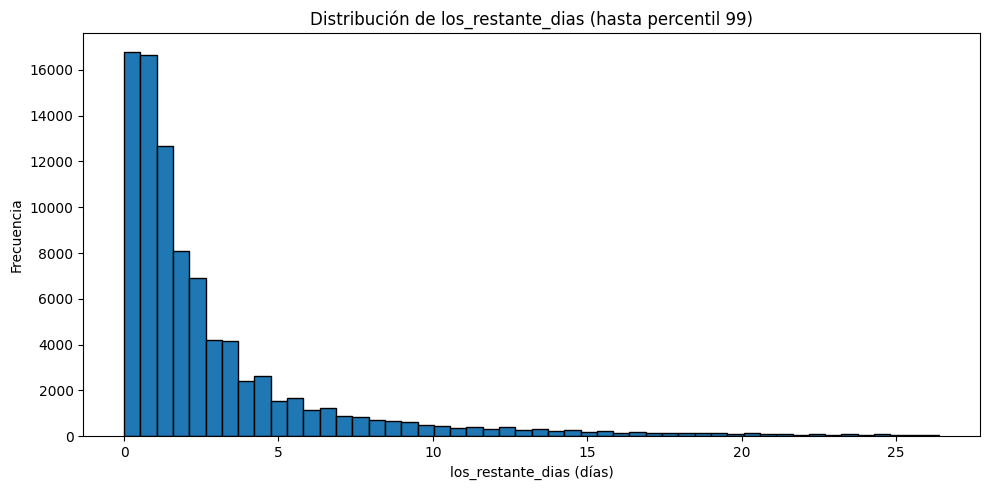

In [11]:
cols_los = [c for c in ["los", "los_restante_dias"] if c in df.columns]
display(df[cols_los].describe(percentiles=[.01,.05,.25,.5,.75,.90,.95,.99]).T)

for col in cols_los:
    limite = df[col].quantile(.99)
    plt.figure(figsize=(10,5))
    plt.hist(df.loc[df[col].notna() & (df[col] <= limite), col], bins=50, edgecolor="black")
    plt.xlabel(f"{col} (días)")
    plt.ylabel("Frecuencia")
    plt.title(f"Distribución de {col} (hasta percentil 99)")
    plt.tight_layout()
    plt.show()


## 10. Variable objetivo: estancia restante mayor a 3 días

Para el análisis se define:

- `0`: estancia restante ≤ 3 días.
- `1`: estancia restante > 3 días.

**Importante:** `los_restante_dias` genera directamente el objetivo y, por tanto, debe excluirse de los predictores.


,n,porcentaje
los_gt_3d,,
0,64246,71.015951
1,26221,28.984049


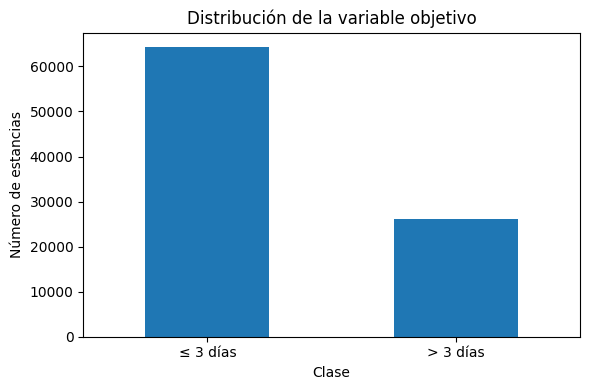

In [12]:
if "los_restante_dias" in df.columns:
    df["los_gt_3d"] = (df["los_restante_dias"] > 3).astype(int)

    target_tabla = pd.DataFrame({
        "n": df["los_gt_3d"].value_counts().sort_index(),
        "porcentaje": df["los_gt_3d"].value_counts(normalize=True).sort_index() * 100
    })
    display(target_tabla)

    plt.figure(figsize=(6,4))
    df["los_gt_3d"].value_counts().sort_index().plot(kind="bar")
    plt.xticks([0,1], ["≤ 3 días", "> 3 días"], rotation=0)
    plt.xlabel("Clase")
    plt.ylabel("Número de estancias")
    plt.title("Distribución de la variable objetivo")
    plt.tight_layout()
    plt.show()


## 11. Signos vitales


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
fc_min,90356.0,73.506676,16.482327,0.000000,39.000000,50.000000,62.000000,72.000000,84.000000,103.000000,116.450000,1.660000e+02
fr_min,90078.0,13.075901,4.471935,0.000000,0.000000,6.000000,11.000000,13.000000,16.000000,20.000000,24.000000,3.600000e+01
pad_min,75174.0,52.301594,13.447062,0.000000,21.000000,32.000000,43.000000,52.000000,61.000000,76.000000,87.000000,1.390000e+02
pam_min,75184.0,64.932217,84.476783,-22767.000000,32.000000,44.000000,56.000000,64.000000,74.000000,90.000000,102.000000,2.240000e+02
pas_min,75185.0,98.909929,19.378925,-2.000000,56.000000,71.000000,86.000000,97.000000,111.000000,133.000000,150.000000,2.470000e+02
spo2_min,90290.0,92.972167,6.266034,-272.000000,71.000000,85.000000,91.000000,94.000000,96.000000,99.000000,100.000000,1.000000e+02
temperatura_min,83080.0,97.549530,3.668313,0.000000,94.100000,96.000000,97.400000,97.800000,98.200000,99.000000,99.900000,1.050000e+02
fc_mean,90356.0,85.208863,17.071294,27.214286,51.490217,60.384615,73.266667,83.357143,95.923077,115.500000,129.461538,7.240769e+02
fr_mean,90078.0,27.355100,1884.220122,0.000000,11.726552,13.571429,16.153846,18.384615,21.300000,26.909091,31.500000,5.385120e+05
pad_mean,75174.0,68.216904,112.548980,0.000000,40.500000,47.333333,57.500000,65.230769,74.000000,88.500000,100.295706,1.141033e+04


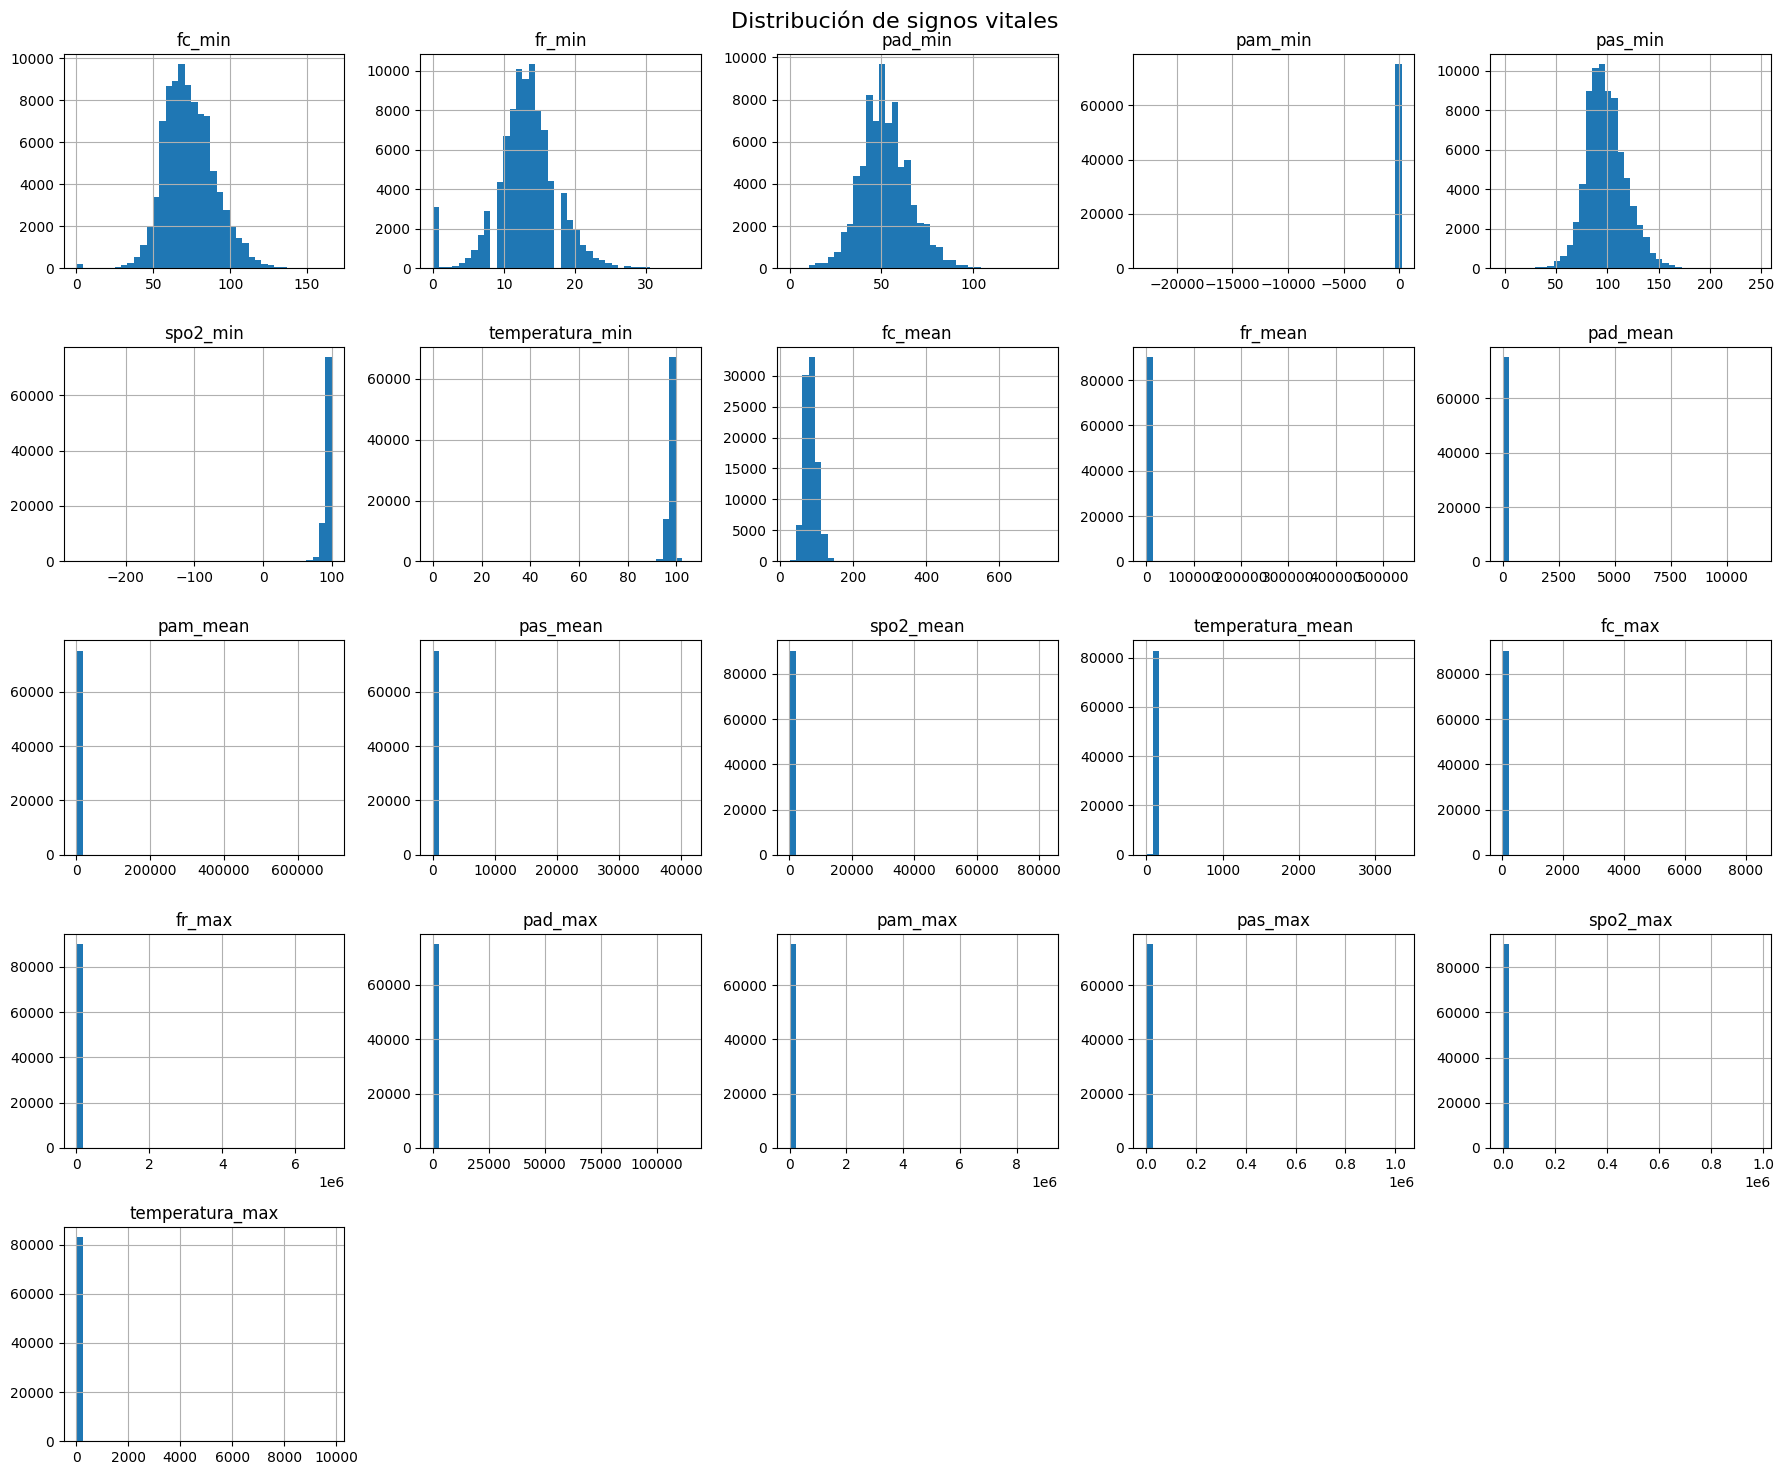

In [13]:
if vitales:
    display(df[vitales].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)
    df[vitales].hist(figsize=(18,15), bins=40)
    plt.suptitle("Distribución de signos vitales", fontsize=16)
    plt.tight_layout()
    plt.show()


## 12. Boxplots de signos vitales


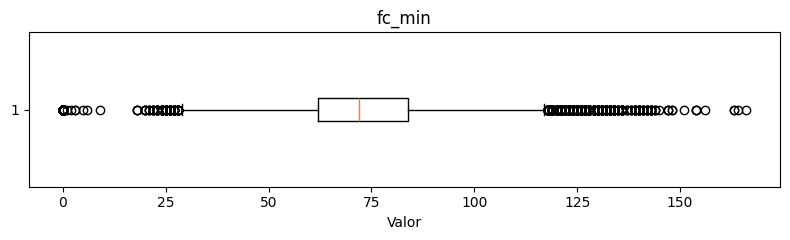

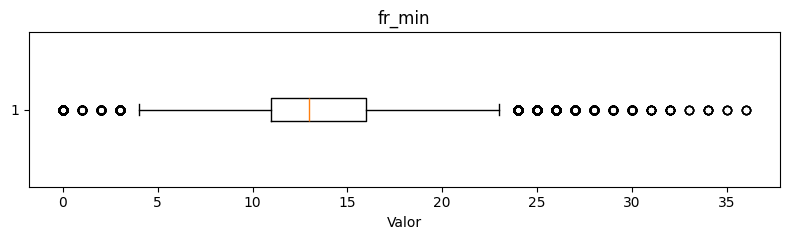

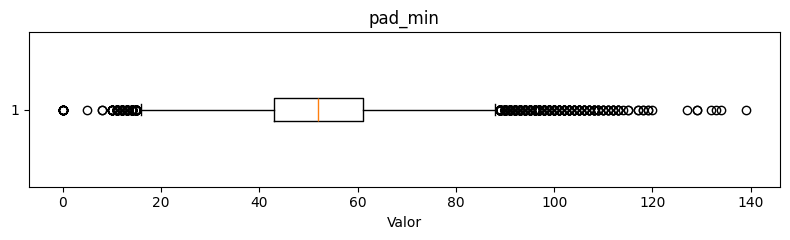

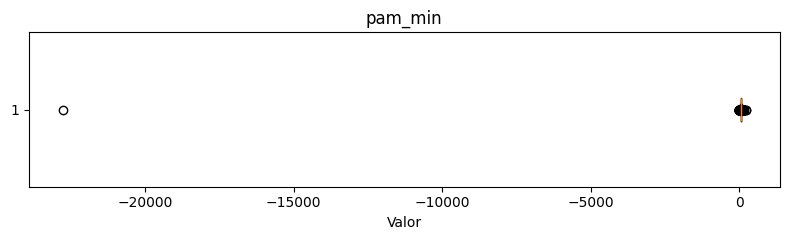

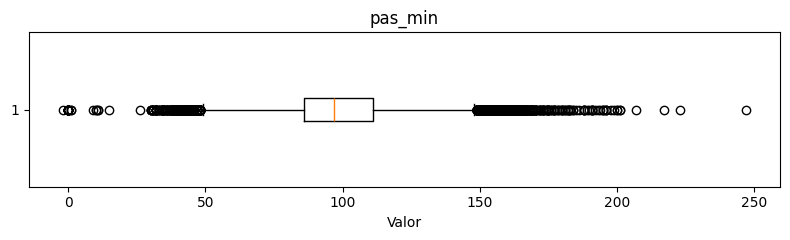

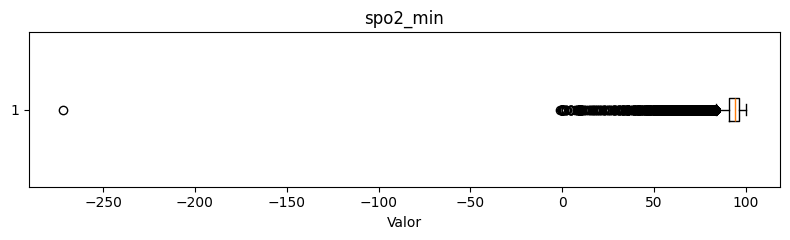

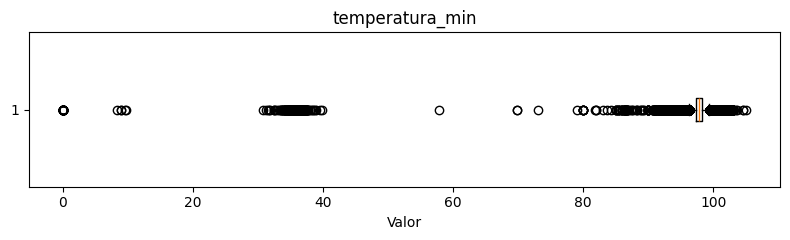

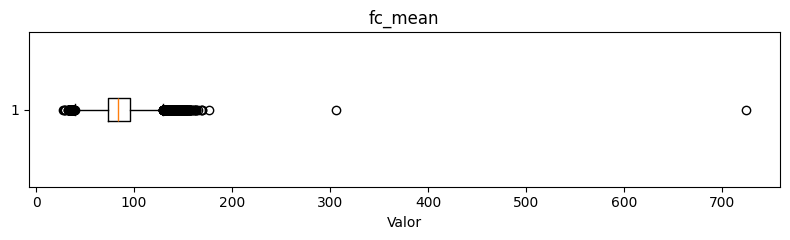

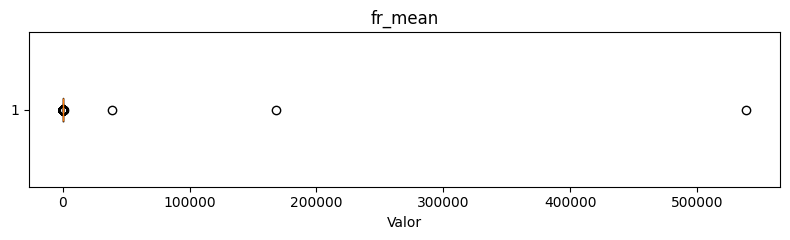

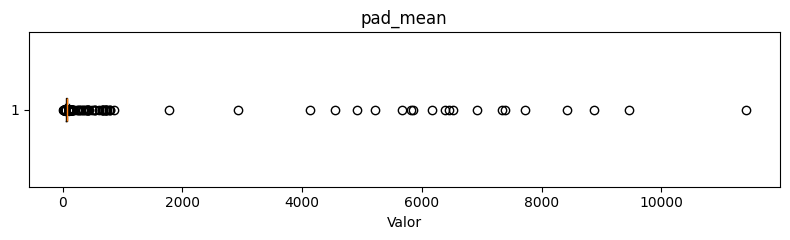

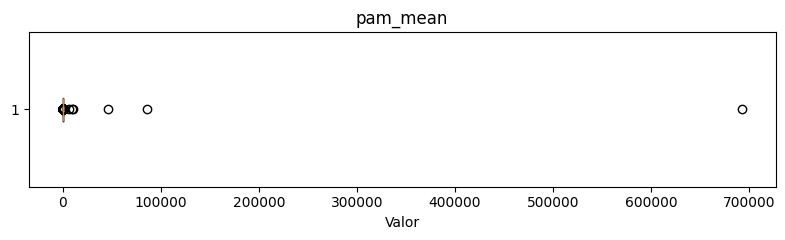

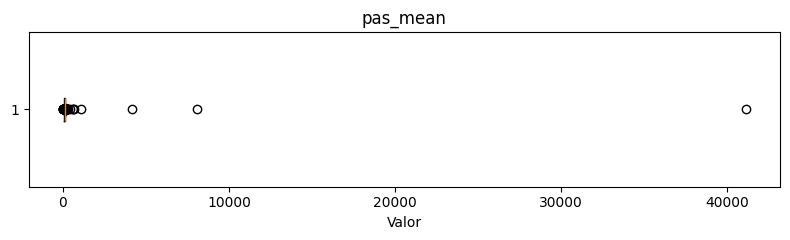

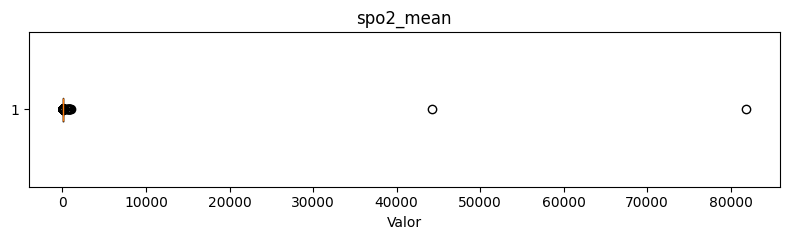

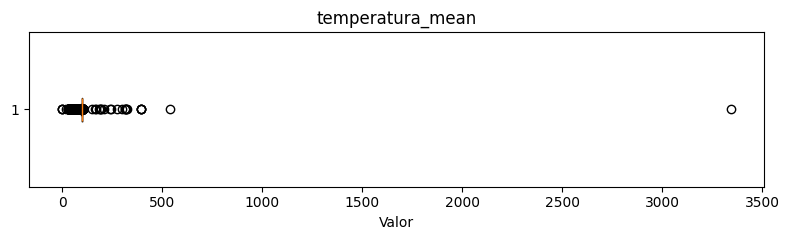

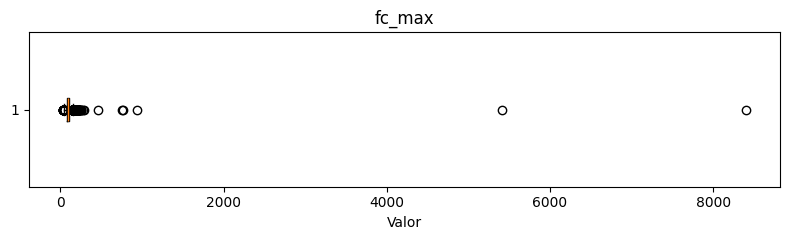

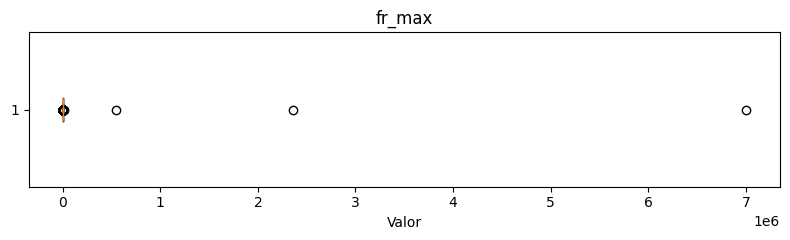

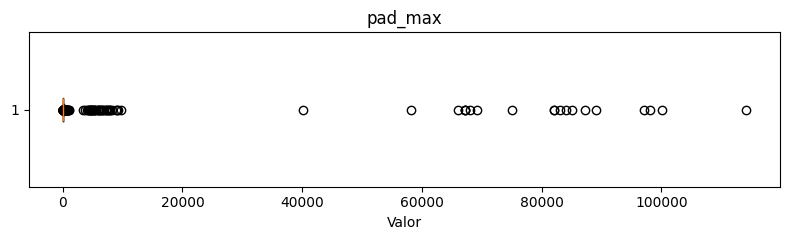

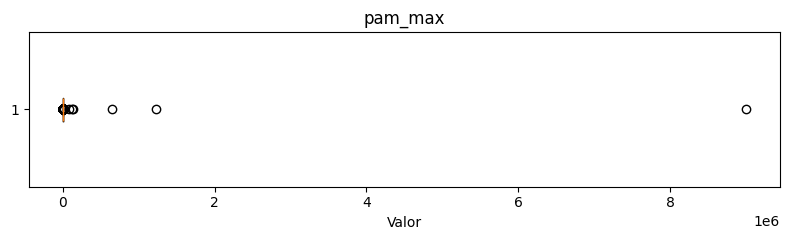

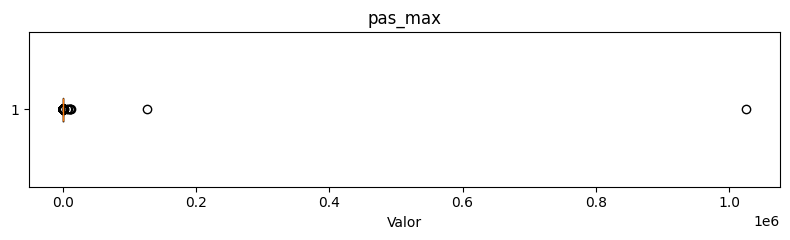

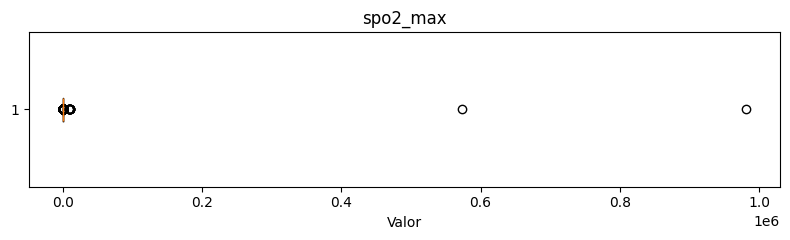

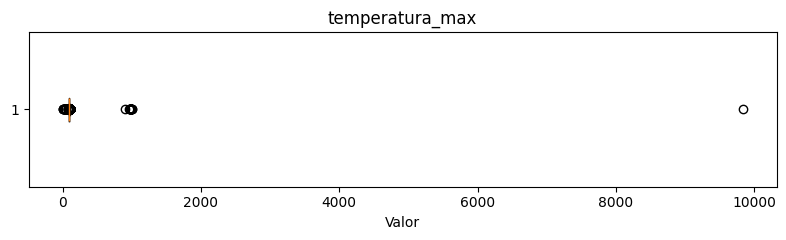

In [14]:
for col in vitales:
    datos = df[col].dropna()
    if len(datos):
        plt.figure(figsize=(8,2.5))
        plt.boxplot(datos, vert=False)
        plt.xlabel("Valor")
        plt.title(col)
        plt.tight_layout()
        plt.show()


## 13. Variables de laboratorio


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
lab_50868_anion_gap,78895.0,14.031269,4.182211,-4.0,6.00,8.00,11.00,14.00,16.00,21.0,28.000,65.00
lab_50882_bicarbonate,79934.0,23.088752,4.563829,2.0,11.00,16.00,21.00,23.00,26.00,30.0,37.000,50.00
lab_50893_calcium_total,69074.0,8.396737,0.822830,0.0,6.40,7.10,7.90,8.40,8.90,9.6,10.427,29.50
lab_50902_chloride,80247.0,103.950444,6.444024,61.0,86.00,93.00,100.00,104.00,108.00,113.0,119.000,151.00
lab_50912_creatinine,80077.0,1.454910,1.592896,0.0,0.40,0.50,0.70,1.00,1.50,4.3,8.500,41.50
lab_50931_glucose,71739.0,141.326587,63.689196,15.0,62.38,80.00,103.00,125.00,160.00,260.0,371.000,1856.00
lab_50960_magnesium,71915.0,2.052493,0.516522,0.3,1.30,1.50,1.80,2.00,2.20,2.8,3.500,40.50
lab_50970_phosphate,69195.0,3.718535,1.377976,0.4,1.30,2.00,2.90,3.50,4.30,6.2,8.600,40.50
lab_50971_potassium,78565.0,4.194252,0.645181,0.8,3.00,3.30,3.80,4.10,4.50,5.3,6.100,11.10
lab_50983_sodium,75642.0,138.342085,5.158000,97.0,123.00,130.00,136.00,139.00,141.00,146.0,151.000,179.00


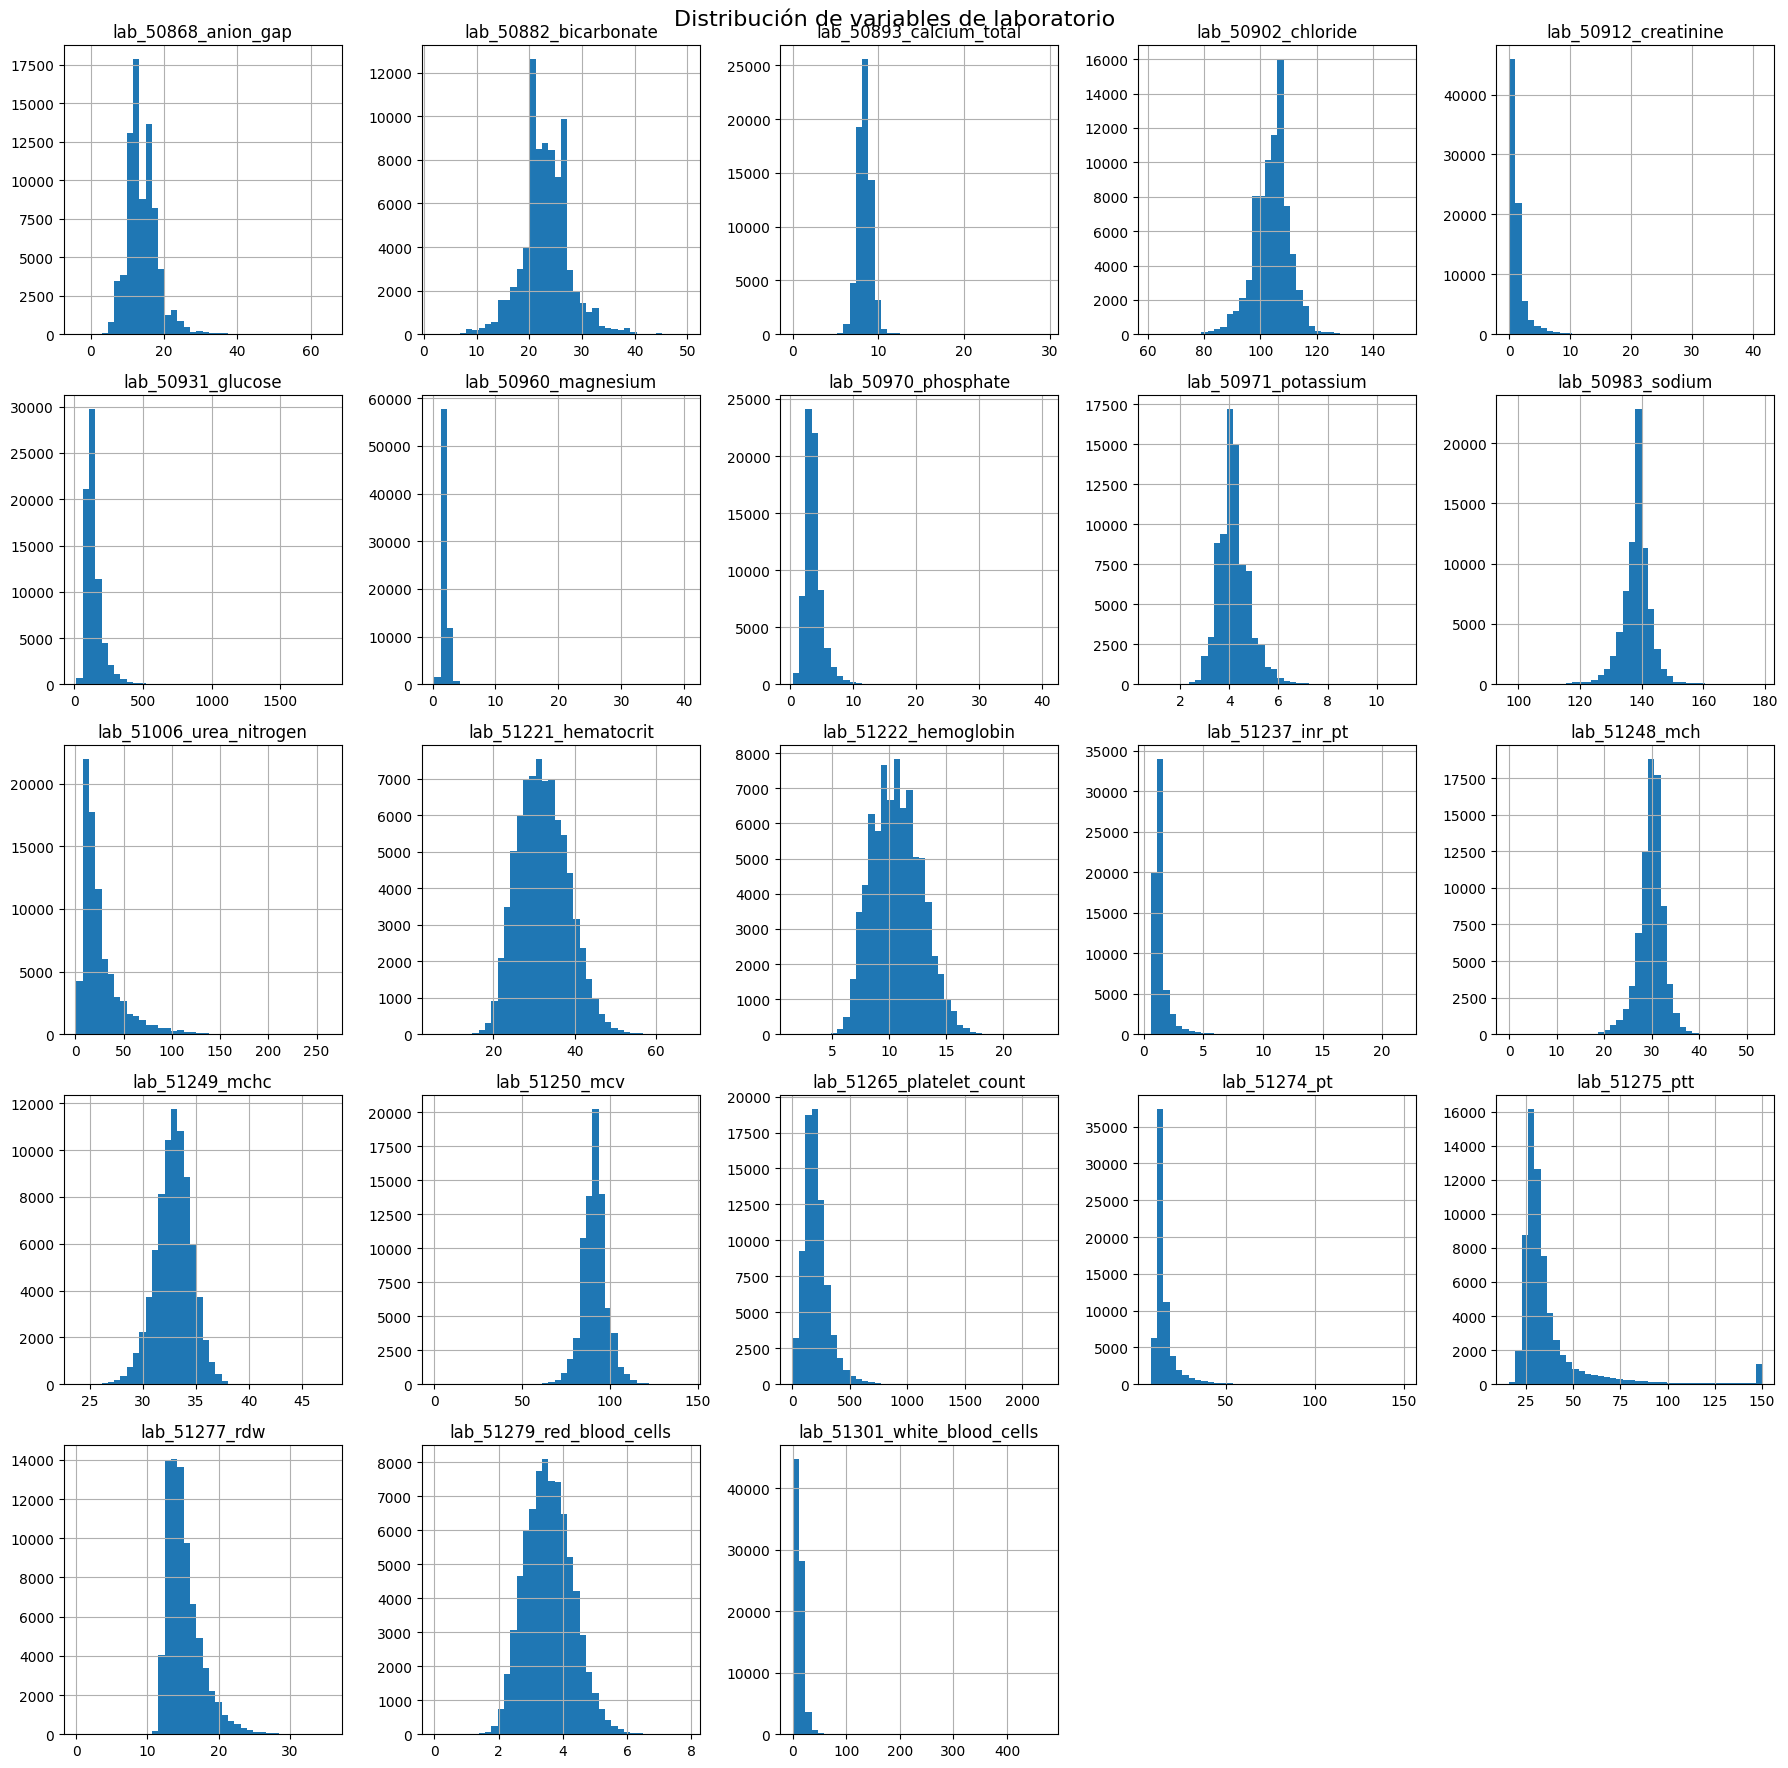

In [15]:
if laboratorios:
    display(df[laboratorios].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T)
    df[laboratorios].hist(figsize=(18,18), bins=40)
    plt.suptitle("Distribución de variables de laboratorio", fontsize=16)
    plt.tight_layout()
    plt.show()


## 14. Detección exploratoria de valores extremos con IQR

Los valores señalados por IQR **no se eliminan automáticamente**. En datos clínicos, una observación extrema puede ser fisiológicamente real y clínicamente relevante.


In [16]:
def resumen_outliers(datos, columnas):
    resultados = []

    for col in columnas:
        x = datos[col].dropna()
        if x.empty:
            continue

        q1 = x.quantile(.25)
        q3 = x.quantile(.75)
        iqr = q3 - q1
        li = q1 - 1.5 * iqr
        ls = q3 + 1.5 * iqr

        mask = (x < li) | (x > ls)

        resultados.append({
            "variable": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "limite_inferior": li,
            "limite_superior": ls,
            "n_outliers": mask.sum(),
            "porcentaje_outliers": mask.mean() * 100
        })

    return pd.DataFrame(resultados)

outliers = resumen_outliers(df, vitales + laboratorios)
display(outliers.sort_values("porcentaje_outliers", ascending=False))


,variable,Q1,Q3,IQR,limite_inferior,limite_superior,n_outliers,porcentaje_outliers
19,spo2_max,99.000000,100.000000,1.000000,97.500000,101.500000,10637,11.780928
40,lab_51275_ptt,27.100000,37.000000,9.900000,12.250000,51.850000,7159,11.047499
39,lab_51274_pt,12.400000,16.000000,3.600000,7.000000,21.400000,6787,10.440254
25,lab_50912_creatinine,0.700000,1.500000,0.800000,-0.500000,2.700000,8057,10.061566
6,temperatura_min,97.400000,98.200000,0.800000,96.200000,99.400000,8259,9.941021
34,lab_51237_inr_pt,1.100000,1.500000,0.400000,0.500000,2.100000,6224,9.575237
31,lab_51006_urea_nitrogen,13.000000,32.000000,19.000000,-15.500000,60.500000,6267,7.831205
20,temperatura_max,98.200000,99.300000,1.100000,96.550000,100.950000,5956,7.168994
13,temperatura_mean,97.800000,98.700000,0.900000,96.450000,100.050000,5406,6.506981
26,lab_50931_glucose,103.000000,160.000000,57.000000,17.500000,245.500000,4378,6.102678


## 15. Matriz de correlación


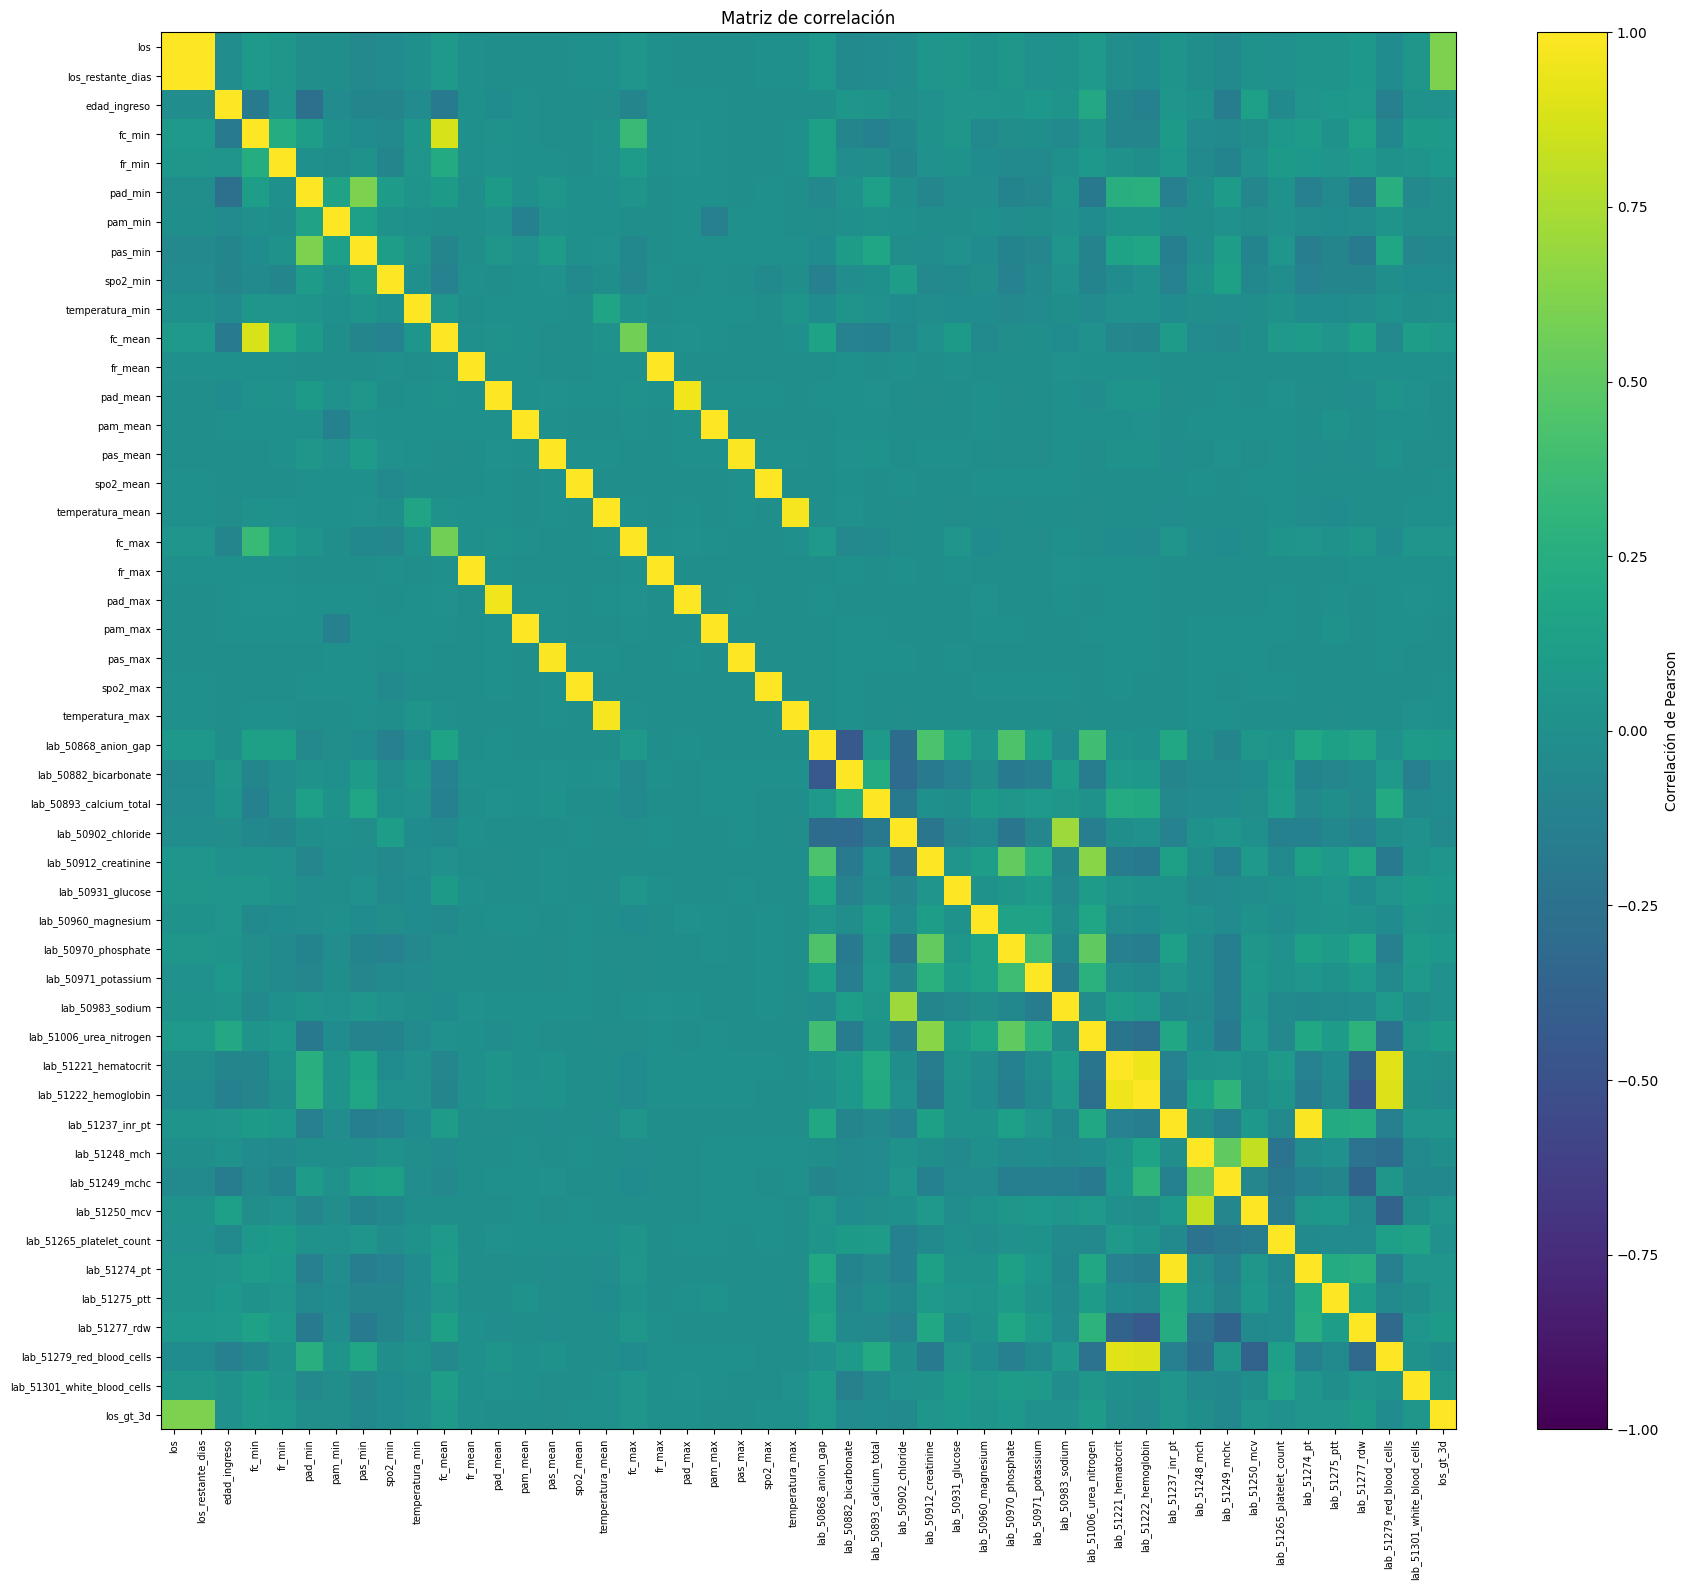

In [17]:
excluir_corr = ["subject_id", "hadm_id", "stay_id"]
variables_corr = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in excluir_corr
]

corr = df[variables_corr].corr()

plt.figure(figsize=(18,16))
plt.imshow(corr, aspect="auto", vmin=-1, vmax=1)
plt.colorbar(label="Correlación de Pearson")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=7)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=7)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()


## 16. Correlación con la estancia restante


,correlacion
pas_min,-0.058256
lab_51249_mchc,-0.053258
lab_50882_bicarbonate,-0.039963
lab_50893_calcium_total,-0.036320
spo2_min,-0.033878
lab_51222_hemoglobin,-0.028716
lab_51279_red_blood_cells,-0.024488
lab_50902_chloride,-0.023416
edad_ingreso,-0.017583
lab_51221_hematocrit,-0.014154


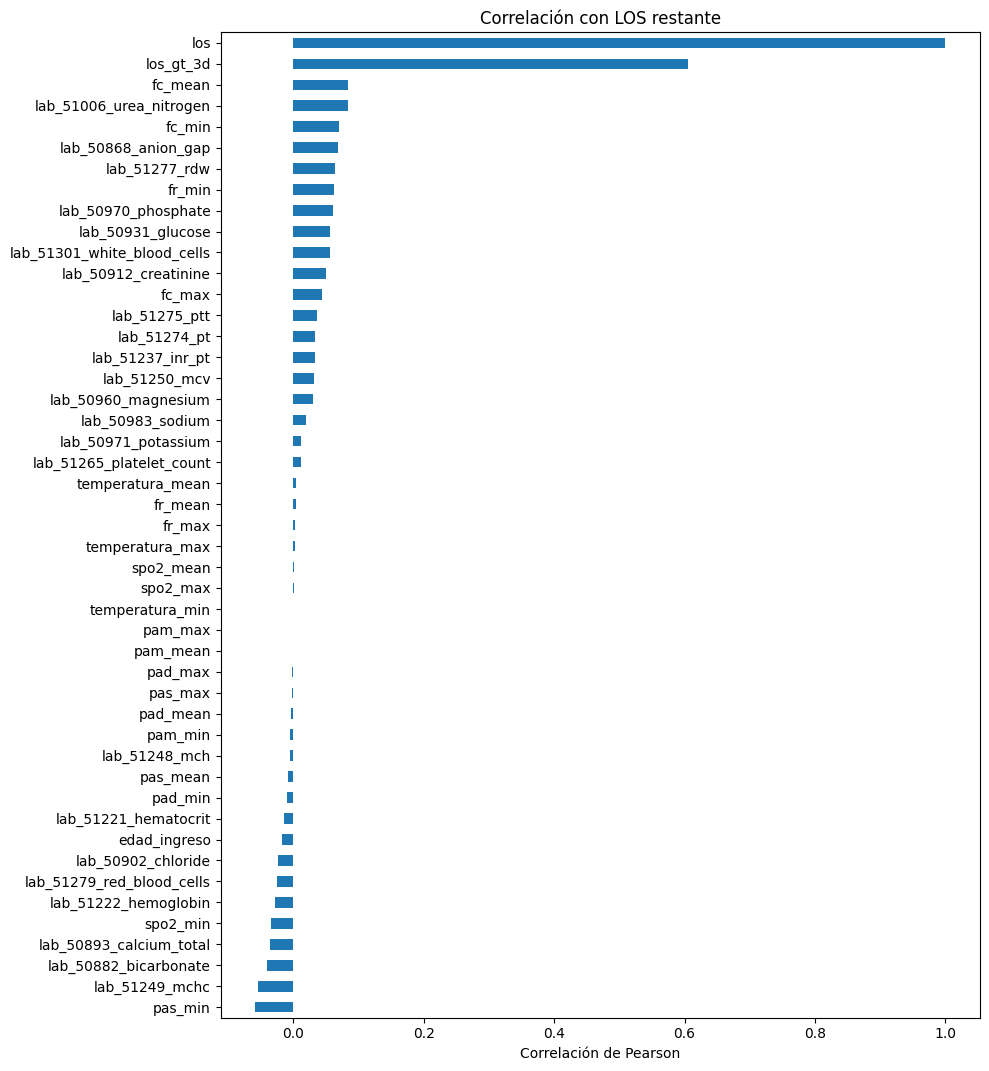

In [18]:
if "los_restante_dias" in corr.columns:
    corr_los = (
        corr["los_restante_dias"]
        .drop(labels=["los_restante_dias"], errors="ignore")
        .sort_values()
    )

    display(corr_los.to_frame("correlacion"))

    plt.figure(figsize=(10, max(7, len(corr_los)*0.23)))
    corr_los.plot(kind="barh")
    plt.xlabel("Correlación de Pearson")
    plt.title("Correlación con LOS restante")
    plt.tight_layout()
    plt.show()


## 17. Correlaciones altas entre predictores


In [19]:
pred_corr_cols = [
    c for c in variables_corr
    if c not in ["los", "los_restante_dias", "los_gt_3d"]
]

corr_pred = df[pred_corr_cols].corr().abs()
upper = corr_pred.where(np.triu(np.ones(corr_pred.shape), k=1).astype(bool))

pares_altos = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0":"variable_1", "level_1":"variable_2", 0:"correlacion_abs"})
    .query("correlacion_abs >= 0.80")
    .sort_values("correlacion_abs", ascending=False)
)

display(pares_altos)


,variable_1,variable_2,correlacion_abs
435,pam_mean,pam_max,0.999891
366,fr_mean,fr_max,0.999751
500,spo2_mean,spo2_max,0.999358
949,lab_51237_inr_pt,lab_51274_pt,0.987932
468,pas_mean,pas_max,0.987249
531,temperatura_mean,temperatura_max,0.969785
401,pad_mean,pad_max,0.956532
924,lab_51221_hematocrit,lab_51222_hemoglobin,0.949824
933,lab_51221_hematocrit,lab_51279_red_blood_cells,0.906384
943,lab_51222_hemoglobin,lab_51279_red_blood_cells,0.896226


## 18. Variables numéricas según el target


In [20]:
if "los_gt_3d" in df.columns:
    clinicas = [c for c in vitales + laboratorios if c in df.columns]

    medias_target = df.groupby("los_gt_3d")[clinicas].mean().T
    display(medias_target)

    if "edad_ingreso" in df.columns:
        print("Edad según clase:")
        display(df.groupby("los_gt_3d")["edad_ingreso"].describe())


los_gt_3d,0,1
fc_min,72.744428,75.378521
fr_min,12.883881,13.547456
pad_min,52.427259,51.997177
pam_min,65.490922,63.579488
pas_min,99.768731,96.829768
spo2_min,93.094759,92.671107
temperatura_min,97.544541,97.562029
fc_mean,84.274510,87.503347
fr_mean,19.355199,47.000984
pad_mean,68.283095,68.056563


Edad según clase:


,count,mean,std,min,25%,50%,75%,max
los_gt_3d,,,,,,,,
0,64246.0,64.67268,16.883630,18.0,55.0,66.0,77.0,103.0
1,26221.0,65.12593,16.038888,18.0,56.0,67.0,77.0,103.0


## 19. Variables categóricas según el target


In [21]:
if "los_gt_3d" in df.columns:
    for col in categoricas:
        print("\n", "="*70)
        print(f"{col} vs los_gt_3d")
        print("="*70)
        tabla = pd.crosstab(df[col], df["los_gt_3d"], normalize="index") * 100
        display(tabla)



gender vs los_gt_3d


los_gt_3d,0,1
gender,,
F,71.674846,28.325154
M,70.499882,29.500118



first_careunit vs los_gt_3d


los_gt_3d,0,1
first_careunit,,
Cardiac Vascular Intensive Care Unit (CVICU),76.716686,23.283314
Coronary Care Unit (CCU),71.255140,28.744860
Intensive Care Unit (ICU),42.424242,57.575758
Med/Surg,100.000000,0.000000
Medical Intensive Care Unit (MICU),70.299838,29.700162
Medical/Surgical Intensive Care Unit (MICU/SICU),75.934771,24.065229
Medicine,12.500000,87.500000
Medicine/Cardiology Intermediate,100.000000,0.000000
Neuro Intermediate,53.808006,46.191994



admission_type vs los_gt_3d


los_gt_3d,0,1
admission_type,,
AMBULATORY OBSERVATION,100.000000,0.000000
DIRECT EMER.,70.178181,29.821819
DIRECT OBSERVATION,97.674419,2.325581
ELECTIVE,77.393349,22.606651
EU OBSERVATION,98.789346,1.210654
EW EMER.,71.438805,28.561195
OBSERVATION ADMIT,67.927607,32.072393
SURGICAL SAME DAY ADMISSION,81.146578,18.853422
URGENT,63.868959,36.131041



admission_location vs los_gt_3d


los_gt_3d,0,1
admission_location,,
AMBULATORY SURGERY TRANSFER,67.164179,32.835821
CLINIC REFERRAL,68.877100,31.122900
EMERGENCY ROOM,73.643237,26.356763
INFORMATION NOT AVAILABLE,61.434978,38.565022
INTERNAL TRANSFER TO OR FROM PSYCH,79.166667,20.833333
PACU,77.215190,22.784810
PHYSICIAN REFERRAL,75.793097,24.206903
PROCEDURE SITE,81.937437,18.062563
TRANSFER FROM HOSPITAL,62.245861,37.754139


## 20. Proporción de estancia prolongada por primera unidad de UCI


,% LOS > 3 días
first_careunit,
Med/Surg,0.000000
Medicine/Cardiology Intermediate,0.000000
Cardiac Vascular Intensive Care Unit (CVICU),23.283314
Medical/Surgical Intensive Care Unit (MICU/SICU),24.065229
Coronary Care Unit (CCU),28.744860
Trauma SICU (TSICU),29.004065
Medical Intensive Care Unit (MICU),29.700162
Surgical Intensive Care Unit (SICU),30.010393
PACU,32.432432


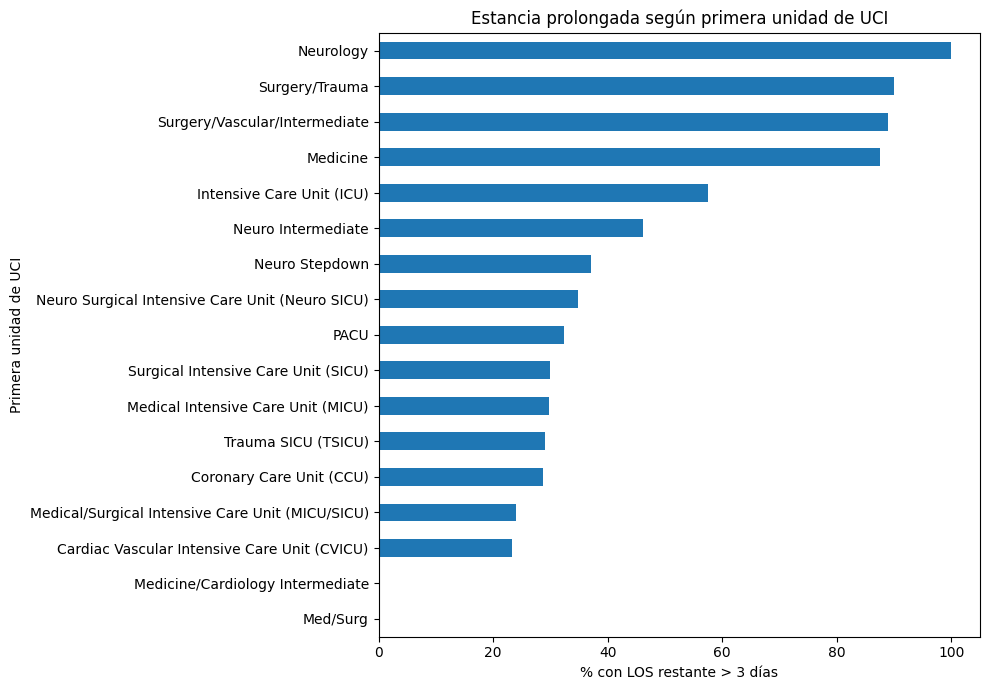

In [22]:
if "first_careunit" in df.columns and "los_gt_3d" in df.columns:
    prop = df.groupby("first_careunit")["los_gt_3d"].mean().sort_values() * 100
    display(prop.to_frame("% LOS > 3 días"))

    plt.figure(figsize=(10,7))
    prop.plot(kind="barh")
    plt.xlabel("% con LOS restante > 3 días")
    plt.ylabel("Primera unidad de UCI")
    plt.title("Estancia prolongada según primera unidad de UCI")
    plt.tight_layout()
    plt.show()


## 21. Patrón de datos faltantes según el target

En datos clínicos, que una prueba no haya sido solicitada puede relacionarse con el proceso asistencial. Por ello se compara la proporción de faltantes entre las dos clases.


In [23]:
if "los_gt_3d" in df.columns:
    missing_por_target = pd.DataFrame({
        "faltantes_clase_0_pct": df.loc[df["los_gt_3d"] == 0].isna().mean() * 100,
        "faltantes_clase_1_pct": df.loc[df["los_gt_3d"] == 1].isna().mean() * 100
    })

    missing_por_target["diferencia_pp"] = (
        missing_por_target["faltantes_clase_1_pct"] -
        missing_por_target["faltantes_clase_0_pct"]
    )

    display(
        missing_por_target
        .assign(abs_diferencia=lambda x: x["diferencia_pp"].abs())
        .sort_values("abs_diferencia", ascending=False)
        .drop(columns="abs_diferencia")
    )


,faltantes_clase_0_pct,faltantes_clase_1_pct,diferencia_pp
lab_50970_phosphate,25.962706,17.512681,-8.450025
lab_50893_calcium_total,26.082558,17.680485,-8.402073
lab_51275_ptt,30.610466,22.878609,-7.731857
lab_50931_glucose,22.915045,15.277831,-7.637215
lab_50960_magnesium,22.715811,15.094771,-7.621040
lab_51274_pt,30.316284,22.813775,-7.502509
lab_51237_inr_pt,30.322510,22.825216,-7.497294
lab_50983_sodium,18.089842,12.215400,-5.874442
lab_50868_anion_gap,13.890359,10.098776,-3.791583
lab_50971_potassium,14.182984,10.640326,-3.542658


## 22. Cantidad de información clínica faltante por estancia


In [24]:
variables_clinicas = vitales + laboratorios

if variables_clinicas:
    df["n_faltantes_clinicos"] = df[variables_clinicas].isna().sum(axis=1)
    df["pct_faltantes_clinicos"] = (
        df["n_faltantes_clinicos"] / len(variables_clinicas) * 100
    )

    display(df[["n_faltantes_clinicos", "pct_faltantes_clinicos"]].describe())

    if "los_gt_3d" in df.columns:
        display(df.groupby("los_gt_3d")["pct_faltantes_clinicos"].describe())


,n_faltantes_clinicos,pct_faltantes_clinicos
count,90467.000000,90467.000000
mean,5.669703,12.885688
std,7.869760,17.885817
min,0.000000,0.000000
25%,0.000000,0.000000
50%,1.000000,2.272727
75%,11.000000,25.000000
max,44.000000,100.000000


,count,mean,std,min,25%,50%,75%,max
los_gt_3d,,,,,,,,
0,64246.0,13.596814,18.223070,0.0,0.0,6.818182,27.272727,100.0
1,26221.0,11.143306,16.905655,0.0,0.0,0.000000,20.454545,100.0


## 23. Variables constantes o de baja cardinalidad


In [25]:
unicos = df.nunique(dropna=False).sort_values()

print("Columnas constantes:")
display(unicos[unicos <= 1].to_frame("n_unicos"))

print("\nColumnas con hasta 5 valores únicos:")
display(unicos[unicos <= 5].to_frame("n_unicos"))


Columnas constantes:


,n_unicos



Columnas con hasta 5 valores únicos:


,n_unicos
gender,2
los_gt_3d,2


## 24. Valores infinitos


In [26]:
num = df.select_dtypes(include=np.number)
infinitos = pd.Series(np.isinf(num).sum(), index=num.columns)
display(infinitos[infinitos > 0].to_frame("n_infinitos"))


,n_infinitos


## 25. Revisión explícita de posibles variables con fuga de información

Para un modelo que hace una predicción a las 12 horas, los predictores deben contener únicamente información disponible hasta ese momento.

Por diseño, deben excluirse al menos:
- `subject_id`, `hadm_id`, `stay_id`: identificadores;
- `los`: duración final de la estancia;
- `los_restante_dias`: desenlace futuro usado para construir el objetivo;
- `los_gt_3d`: variable objetivo.

La inclusión final de cada predictor clínico debe verificarse contra la forma en que fue construido en el pipeline de integración.


In [27]:
columnas_no_predictoras = [
    c for c in [
        "subject_id", "hadm_id", "stay_id",
        "los", "los_restante_dias", "los_gt_3d"
    ]
    if c in df.columns
]

predictoras_candidatas = [
    c for c in df.columns
    if c not in columnas_no_predictoras
]

print("Excluir del conjunto X:")
print(columnas_no_predictoras)

print(f"\nNúmero de predictoras candidatas: {len(predictoras_candidatas)}")
print(predictoras_candidatas)


Excluir del conjunto X:
['subject_id', 'hadm_id', 'stay_id', 'los', 'los_restante_dias', 'los_gt_3d']

Número de predictoras candidatas: 51
['edad_ingreso', 'gender', 'first_careunit', 'admission_type', 'admission_location', 'fc_min', 'fr_min', 'pad_min', 'pam_min', 'pas_min', 'spo2_min', 'temperatura_min', 'fc_mean', 'fr_mean', 'pad_mean', 'pam_mean', 'pas_mean', 'spo2_mean', 'temperatura_mean', 'fc_max', 'fr_max', 'pad_max', 'pam_max', 'pas_max', 'spo2_max', 'temperatura_max', 'lab_50868_anion_gap', 'lab_50882_bicarbonate', 'lab_50893_calcium_total', 'lab_50902_chloride', 'lab_50912_creatinine', 'lab_50931_glucose', 'lab_50960_magnesium', 'lab_50970_phosphate', 'lab_50971_potassium', 'lab_50983_sodium', 'lab_51006_urea_nitrogen', 'lab_51221_hematocrit', 'lab_51222_hemoglobin', 'lab_51237_inr_pt', 'lab_51248_mch', 'lab_51249_mchc', 'lab_51250_mcv', 'lab_51265_platelet_count', 'lab_51274_pt', 'lab_51275_ptt', 'lab_51277_rdw', 'lab_51279_red_blood_cells', 'lab_51301_white_blood_cells', 

## 26. Resumen final del EDA


In [28]:
print("=" * 70)
print("RESUMEN DEL DATASET ANALÍTICO MIMIC-IV")
print("=" * 70)

print(f"\nObservaciones: {len(df):,}")
print(f"Variables actuales: {df.shape[1]}")

for col, nombre in [
    ("subject_id", "Pacientes únicos"),
    ("hadm_id", "Admisiones únicas"),
    ("stay_id", "Estancias UCI únicas")
]:
    if col in df.columns:
        print(f"{nombre}: {df[col].nunique():,}")

if "edad_ingreso" in df.columns:
    print(f"\nEdad media: {df['edad_ingreso'].mean():.2f} años")
    print(f"Edad mediana: {df['edad_ingreso'].median():.2f} años")

if "los" in df.columns:
    print(f"\nLOS medio: {df['los'].mean():.2f} días")
    print(f"LOS mediano: {df['los'].median():.2f} días")

if "los_restante_dias" in df.columns:
    print(f"\nLOS restante medio: {df['los_restante_dias'].mean():.2f} días")
    print(f"LOS restante mediano: {df['los_restante_dias'].median():.2f} días")

if "los_gt_3d" in df.columns:
    print("\nDistribución del target:")
    print(pd.DataFrame({
        "n": df["los_gt_3d"].value_counts().sort_index(),
        "porcentaje": df["los_gt_3d"].value_counts(normalize=True).sort_index() * 100
    }))

print("\n15 variables con mayor porcentaje de faltantes:")
print((df.isna().mean() * 100).sort_values(ascending=False).head(15))

print("\nFilas duplicadas:", df.duplicated().sum())
if "stay_id" in df.columns:
    print("stay_id duplicados:", df["stay_id"].duplicated().sum())


RESUMEN DEL DATASET ANALÍTICO MIMIC-IV

Observaciones: 90,467
Variables actuales: 57
Pacientes únicos: 63,487
Admisiones únicas: 82,422
Estancias UCI únicas: 90,467

Edad media: 64.80 años
Edad mediana: 66.00 años

LOS medio: 3.78 días
LOS mediano: 2.05 días

LOS restante medio: 3.28 días
LOS restante mediano: 1.55 días

Distribución del target:
               n  porcentaje
los_gt_3d                   
0          64246   71.015951
1          26221   28.984049

15 variables con mayor porcentaje de faltantes:
lab_51275_ptt              28.369461
lab_51237_inr_pt           28.149491
lab_51274_pt               28.141753
lab_50893_calcium_total    23.647297
lab_50970_phosphate        23.513546
lab_50931_glucose          20.701471
lab_50960_magnesium        20.506925
pad_mean                   16.904507
pad_min                    16.904507
pad_max                    16.904507
pam_mean                   16.893453
pam_min                    16.893453
pam_max                    16.893453
pas_me